#Jupyter notebook for BAT integration

Human BAT Integration

In [1]:
import cobra
print(cobra.__version__)
import optlang
print(optlang.__version__)

# Check actual GLPK version
import subprocess
result = subprocess.run(['glpsol', '--version'], capture_output=True, text=True)
print(result.stdout)


0.29.0
1.8.2
GLPSOL: GLPK LP/MIP Solver, v4.65
Copyright (C) 2000-2017 Andrew Makhorin, Department for Applied
Informatics, Moscow Aviation Institute, Moscow, Russia. All rights
reserved. E-mail: <mao@gnu.org>.

This program has ABSOLUTELY NO WARRANTY.

This program is free software; you may re-distribute it under the terms
of the GNU General Public License version 3 or later.



In [2]:
import sys
import cobra
print(f"Python: {sys.version}")
print(f"COBRApy: {cobra.__version__}")

Python: 3.8.20 (default, Oct  3 2024, 15:19:54) [MSC v.1929 64 bit (AMD64)]
COBRApy: 0.29.0


In [3]:
import cobra
print(cobra.__version__)


0.29.0


In [4]:
import sys
print(sys.executable)
print(sys.version)

import cobra
print(cobra.__version__)

c:\Users\cayle\miniconda3\envs\mitomammal\python.exe
3.8.20 (default, Oct  3 2024, 15:19:54) [MSC v.1929 64 bit (AMD64)]
0.29.0


In [5]:
# Anywhere there is "###" indicates that I have either changed 
# or added code to the default notebook in the forthcoming lines of code
# I have commented out all BAT simulations, and 
# will run those in a separate notebook.

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import cobra
import os
from efflux_method import *
from os.path import join
from cobra.util import create_stoichiometric_matrix
from cobra.util.solver import linear_reaction_coefficients
from cobra.io import read_sbml_model, write_sbml_model
from cobra.flux_analysis import pfba
from time import sleep
from cobra.flux_analysis import flux_variability_analysis
###
#Running in the Python 3.8.20 Kernel 
#Made sure that efflux.py in same file as this notebook!
import matplotlib.colors as mcolors
import matplotlib.cm as cm


In [7]:
#Supplementary Figure 1 - Glucose import and ATP production

In [8]:
model = cobra.io.read_sbml_model(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\6_universal_mito_model.xml")

In [9]:
#setting the objective function 
model.objective = model.reactions[70]
linear_reaction_coefficients(model)

{<Reaction OF_ATP_mitoMap at 0x264d16e8580>: 1.0}

#set all uptake reactions to 0, except glucose and oxygen
model.reactions.EX_acac_e.bounds = (0,0)
model.reactions.EX_ala_L_e.bounds = (0,0)
model.reactions.EX_arg_L_e.bounds = (0,0)
model.reactions.EX_asn_L_e.bounds = (0,0)
model.reactions.EX_asp_L_e.bounds = (0,0)
model.reactions.EX_bhb_e.bounds = (0,0)
model.reactions.EX_cys_L_e.bounds = (0,0)
model.reactions.EX_gly_e.bounds = (0,0)
model.reactions.EX_glyc_e.bounds = (0,0)
model.reactions.EX_h_e.bounds = (0,0)
model.reactions.EX_hco3_e.bounds = (0,0)
model.reactions.EX_hdca_e.bounds = (0,0)
model.reactions.EX_his_L_e.bounds = (0,0)
model.reactions.EX_ile_L_e.bounds = (0,0)
model.reactions.EX_lac_L_e.bounds = (0,0)
model.reactions.EX_leu_L_e.bounds = (0,0)
model.reactions.EX_lys_L_e.bounds = (0,0)
model.reactions.EX_pro_L_e.bounds = (0,0)
model.reactions.EX_ser_L_e.bounds = (0,0)
model.reactions.EX_so3_e.bounds = (0,0)
model.reactions.EX_thr_L_e.bounds = (0,0)
model.reactions.EX_val_L_e.bounds = (0,0)
model.reactions.EX_glc_D_e.bounds = (-1000,0)
model.reactions.EX_o2_e.bounds = (-1000,0)

solution = model.optimize()
print(solution)

glucose_transport_1 = []#model.reaction[26]
ATP_production_1 = []#model.reaction[70]

#model.reactions.EX_glc_D_e.bounds
for i in range(0,5,1): 
	model.reactions[26].lower_bound = - i
	model.reactions[26].upper_bound = i
	ATPsolution = model.optimize()         
	ATP_production_1.append(ATPsolution.objective_value)
	glucose_transport_1.append(model.reactions[26].lower_bound)

#X_data_plot = (0,30,1) #a vector that contains the same information as 

plt.plot(glucose_transport_1, ATP_production_1)

plt.ylabel('ATP production')
plt.xlabel('Glucose import')
plt.show()

#to improve clarty of the graph, I need to invert X axis, and remove the negative - Exchange reactions are modelled
#as negative uptake, so -30 means -30 import.

new_glc_transport1 = range(0,5,1)

plt.plot(new_glc_transport1, ATP_production_1, color = '#A3000B')

plt.ylabel('ATP production', fontsize=14)
plt.xlabel('glucose import', fontsize=14)
plt.show()

1 molecule of imported glucose produces 31 molecules of ATP

In [10]:
data_dir= (r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data")

In [11]:
data_fbat = pd.read_csv((join(data_dir, r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\fBAT_vs_iPSC (4).csv")))

In [12]:
data_fbat

,Row.names,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,fBAT_1,fBAT_2,fBAT_3,Mean_fBAT,iPSC_BA_1,iPSC_BA_2,iPSC_BA_3,Mean_iPSC_BA,Gene
0,ENSG00000000003,916.532848,0.083847,0.190846,0.439345,6.604116e-01,8.014744e-01,612.604014,560.414932,514.271045,562.429997,612.053164,586.663408,588.742941,595.819838,TSPAN6
1,ENSG00000000005,598.773626,-3.889502,0.554859,-7.009898,2.384917e-12,6.107557e-11,968.673684,3910.145514,2377.191667,2418.670289,132.546545,183.591137,173.710373,163.282685,TNMD
2,ENSG00000000419,444.156524,0.180388,0.126875,1.421776,1.550914e-01,2.991652e-01,334.520785,340.567393,344.596585,339.894921,421.030202,364.421505,368.224384,384.558697,DPM1
3,ENSG00000000457,126.726750,-0.263096,0.185195,-1.420646,1.554197e-01,2.996118e-01,121.084211,177.644663,142.561531,147.096802,129.622724,114.571913,122.741461,122.312033,SCYL3
4,ENSG00000000460,68.771296,-0.194686,0.207111,-0.940008,3.472135e-01,5.287091e-01,69.777342,86.368676,78.714956,78.286991,63.349452,63.497687,78.013641,68.286926,C1orf112
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60651,ENSG00000288640,0.319881,0.000000,4.562036,0.000000,1.000000e+00,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,AC005192.1
60652,ENSG00000288642,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,CDR1
60653,ENSG00000288643,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,AC114982.2
60654,ENSG00000288644,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,AC114402.2


In [13]:
model_fbat = cobra.io.read_sbml_model(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\6_universal_mito_model.xml")

In [14]:
list_of_genes=[] 
for gene in model_fbat.genes:
    list_of_genes.append(gene.id)

In [15]:
fbat_dictionary = read_csv_data(path=join(data_dir, r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\fBAT_vs_iPSC (4).csv"), #mTERF4_Inge_prot.csv
                                  list_of_genes=list_of_genes,
                                  id_gene=0,
                                  id_val=10,#check
                                  head=True)

In [16]:
data = pd.read_csv(r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data\fBAT_vs_iPSC (4).csv")
print(data.columns.tolist())   # see all column names
print(data.iloc[:5, 10])       # see what column 10 looks like


['Row.names', 'baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj', 'fBAT_1', 'fBAT_2', 'fBAT_3', 'Mean_fBAT', 'iPSC_BA_1', 'iPSC_BA_2', 'iPSC_BA_3', 'Mean_iPSC_BA', 'Gene']
0     562.429997
1    2418.670289
2     339.894921
3     147.096802
4      78.286991
Name: Mean_fBAT, dtype: float64


In [17]:
#setting the objective function 
model_fbat.objective = model_fbat.reactions[420] #UCP1 production

linear_reaction_coefficients(model_fbat)

{<Reaction HtmB_mitoMap at 0x264d2197ca0>: 1.0}

In [18]:
#constrain the model using EFLUX
#Eflux(model_fbat,fbat_dictionary,2000,1, ignore_mus=True)
Eflux(model_fbat,fbat_dictionary,2000,1, ignore_mus=True)

In [19]:
#perform FBA
solution_fbat = model_fbat.optimize()
pfba_solution_fbat = cobra.flux_analysis.pfba(model_fbat)
print(solution_fbat, pfba_solution_fbat)

<Solution 98.074 at 0x264d2300ca0> <Solution 1244.876 at 0x264d2316850>


In [20]:
model = model_fbat

c=0
e=0
for reaction in model.reactions:
    c+= reaction._upper_bound != 50.0 and reaction._upper_bound != 1000.0
    e+= reaction._upper_bound == 1000.0
u = len(model.reactions) - c - e
print(f"There are:{c} constrained reactions\n           {u} unconstrained reactions\n           {e} exchange reactions")

There are:488 constrained reactions
           0 unconstrained reactions
           72 exchange reactions


In [21]:
model_fbat.summary()



Metabolite,Reaction,Flux,C-Number,C-Flux
akg_e,EX_akg_e,2.225,5,4.32%
argsuc_e,EX_argsuc_e,0.2697,10,1.05%
asn_L_e,EX_asn_L_e,0.6415,4,1.00%
asp_L_e,EX_asp_L_e,0.046,4,0.07%
but_e,EX_but_e,0.4653,4,0.72%
cit_e,EX_cit_e,2.227,6,5.19%
fe2_e,EX_fe2_e,1.718,0,0.00%
for_e,EX_for_e,4.372,1,1.70%
fum_e,EX_fum_e,2.491,4,3.87%
glc_D_e,EX_glc_D_e,5.229,6,12.19%


In [22]:
formatted = pfba_solution_fbat.fluxes.apply(lambda x: f"{x:.10f}")
print(formatted.to_string())

flux_table = formatted.reset_index()
flux_table.columns = ["Reaction", "Flux"]
save_path = r"C:\Users\cayle\OneDrive\Documents\MitoMammal Author Data"
# Display table

print(flux_table.to_string(index=False))
# Save to Excel file
flux_table.to_csv("Human.Transcriptomic.flux_S2__table.csv", index=False)

EX_2hb_e                     0.0000000000
EX_ac_e                      0.0000000000
EX_acac_e                    0.0000000000
EX_akg_e                    -2.2246863256
EX_ala_B_e                   0.0000000000
EX_ala_L_e                  14.8326047941
EX_arg_L_e                   0.0000000000
EX_argsuc_e                 -0.2697459035
EX_asn_L_e                  -0.6415077485
EX_asp_L_e                  -0.0460021683
EX_bhb_e                     0.0000000000
EX_bilirub_e                 0.0000000000
EX_biomass_e                 1.7181879053
EX_but_e                    -0.4652570052
EX_chol_e                    0.0000000000
EX_cit_e                    -2.2274146078
EX_citr_L_e                  0.0000000000
EX_co_e                      0.0000000000
EX_co2_e                    51.4196328705
EX_creat_e                   0.0000000000
EX_cyan_e                    0.0000000000
EX_cys_L_e                   0.0000000000
EX_etoh_e                    0.0000000000
EX_fe2_e                    -1.718

In [23]:
sol = pfba(model_fbat)
print(sol)

<Solution 1244.876 at 0x264d27c9400>


In [24]:
fbat_uptake_metabolites = ['a-ketogluterate','argininosuccinate', 'aspartate', 'butanoic acid','citrate',
                           'fe2', 'formate','fumarate', 'glucose', 'glutamine', 'glycine','H','O2','oxaloacetate']
fbat_uptake_flux = [
                    sol.fluxes['EX_akg_e'],
                    sol.fluxes['EX_argsuc_e'],
                    sol.fluxes['EX_asp_L_e'],
                    sol.fluxes['EX_but_e'],
                    sol.fluxes['EX_cit_e'],
                    sol.fluxes['EX_fe2_e'],
                    sol.fluxes['EX_for_e'],
                    sol.fluxes['EX_fum_e'],
                    sol.fluxes['EX_glc_D_e'],
                    sol.fluxes['EX_gln_L_e'],
                    sol.fluxes['EX_gly_e'],
                    sol.fluxes['EX_h_e'],
                    sol.fluxes['EX_o2_e'],
                    sol.fluxes['EX_oaa_e']
                   ]

In [25]:
fbat_secretion_metabolites = ['alanine', 'CO2', 'H20', 'hexadecanoic acid', 'lactate', 'malate', 'NH4', 'proline',
                              'serine', 'succinate', 'urea']
fbat_secretion_flux = [
                       sol.fluxes['EX_ala_L_e'],
                       sol.fluxes['EX_co2_e'],
                       sol.fluxes['EX_h2o_e'],
                       sol.fluxes['EX_hdca_e'],
                       sol.fluxes['EX_lac_L_e'],
                       sol.fluxes['EX_mal_L_e'],
                       sol.fluxes['EX_nh4_e'],
                       sol.fluxes['EX_pro_L_e'],
                       sol.fluxes['EX_ser_L_e'],
                       sol.fluxes['EX_succ_e'],
                       sol.fluxes['EX_urea_e'],
                      ]     

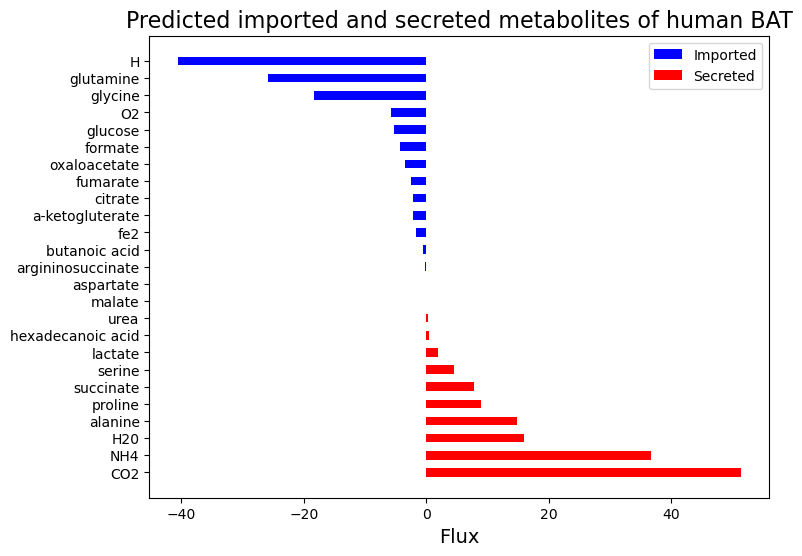

In [26]:
# Sort metabolites and fluxes based on flux values
sorted_uptake_metabolites, sorted_uptake_flux = zip(*sorted(zip(fbat_uptake_metabolites, fbat_uptake_flux), key=lambda x: x[1], reverse=True))
sorted_secretion_metabolites, sorted_secretion_flux = zip(*sorted(zip(fbat_secretion_metabolites, fbat_secretion_flux), key=lambda x: x[1], reverse=True))

# Create figure and axis objects
fig, ax = plt.subplots(figsize=(8, 6))  # Adjust the size as needed

# Plot secreted metabolites first
ax.barh(sorted_secretion_metabolites, sorted_secretion_flux, color='red', label='Secreted', height=0.5)

# Plot imported metabolites
ax.barh(sorted_uptake_metabolites, sorted_uptake_flux, color='blue', label='Imported', height=0.5)

# Add labels and title with increased font size
ax.set_xlabel('Flux', fontsize=14)  # Increase font size here
ax.set_title('Predicted imported and secreted metabolites of human BAT', fontsize=16)  # Increase font size here

# Get the handles and labels of the legend
handles, labels = ax.get_legend_handles_labels()

# Reorder the handles and labels
handles = [handles[1], handles[0]]
labels = [labels[1], labels[0]]

# Create the legend with the reordered handles and labels
ax.legend(handles, labels)
# Save the figure as SVG
plt.savefig('human_BAT_rna.svg', format='svg')

# Show plot
plt.show()

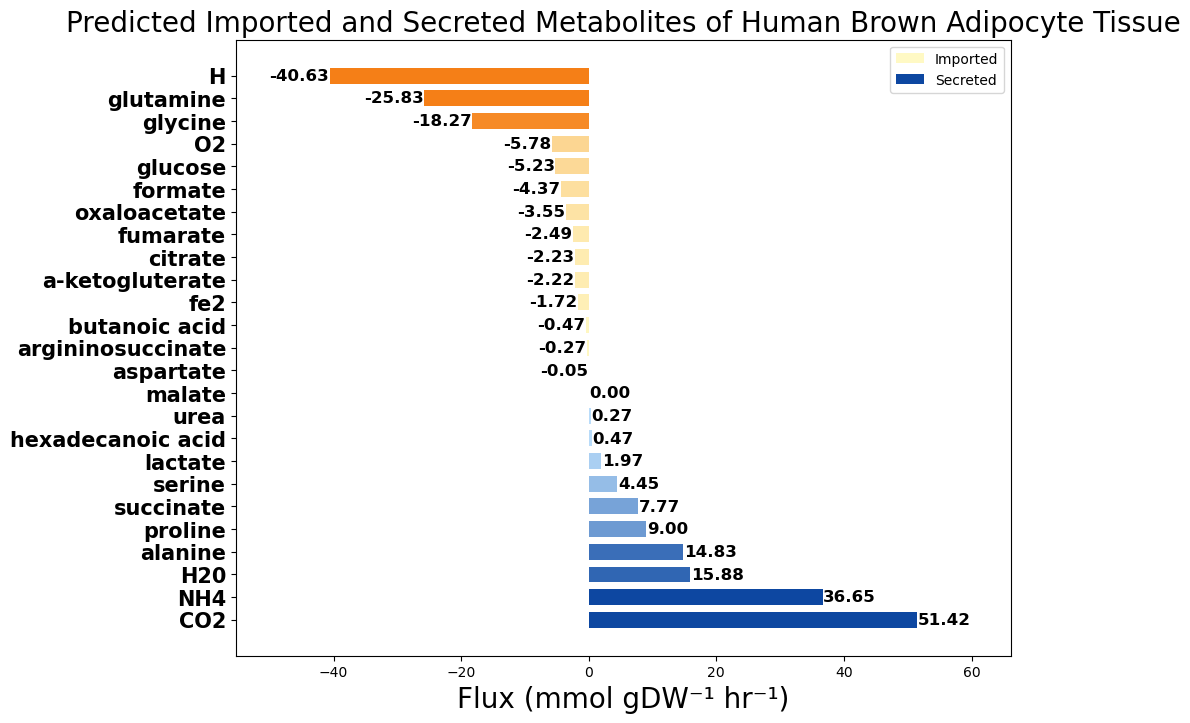

In [27]:
### My graph
# Sort metabolites and fluxes based on flux values
sorted_uptake_metabolites, sorted_uptake_flux = zip(*sorted(zip(fbat_uptake_metabolites, fbat_uptake_flux), key=lambda x: x[1], reverse=True))
sorted_secretion_metabolites, sorted_secretion_flux = zip(*sorted(zip(fbat_secretion_metabolites, fbat_secretion_flux), key=lambda x: x[1], reverse=True))


fig, ax = plt.subplots(figsize=(10, 8)) 

uptake_norm = mcolors.Normalize(vmin=0, vmax=20)   
secretion_norm = mcolors.Normalize(vmin=0, vmax=20)   

uptake_cmap = mcolors.LinearSegmentedColormap.from_list(
    'yellow_ombre', ['#FFF9C4', '#F57F17']
)
secretion_cmap = mcolors.LinearSegmentedColormap.from_list(
    'blue_ombre', ['#BBDEFB', '#0D47A1']
)

uptake_colors = [uptake_cmap(uptake_norm(abs(v))) for v in sorted_uptake_flux]
secretion_colors = [secretion_cmap(secretion_norm(abs(v))) for v in sorted_secretion_flux]

ax.barh(sorted_secretion_metabolites, sorted_secretion_flux, color=secretion_colors, label='Secreted', height=0.7)
ax.barh(sorted_uptake_metabolites, sorted_uptake_flux, color=uptake_colors, label='Imported', height=0.7)
from matplotlib.colorbar import ColorbarBase
import matplotlib.gridspec as gridspec

full_cmap = mcolors.LinearSegmentedColormap.from_list('full_ombre', [
    '#0D47A1',   # dark blue (high uptake)
    '#BBDEFB',   # light blue
    '#EEF0D8',   # neutral transition
    '#FFF9C4',   # light yellow
    '#F57F17'    # dark yellow/amber (high secretion)
])

for metabolite, flux in zip(sorted_uptake_metabolites, sorted_uptake_flux):
    ax.text(flux - 0.1, metabolite, f'{flux:.2f}', va='center', ha='right', fontsize=12, fontweight= 'bold')

for metabolite, flux in zip(sorted_secretion_metabolites, sorted_secretion_flux):
    ax.text(flux + 0.1, metabolite, f'{flux:.2f}', va='center', ha='left', fontsize=12, fontweight= 'bold')

ax.set_xlabel('Flux (mmol gDW⁻¹ hr⁻¹)', fontsize=20) 
ax.set_title('Predicted Imported and Secreted Metabolites of Human Brown Adipocyte Tissue', fontsize=20)  

handles, labels = ax.get_legend_handles_labels()
ax.tick_params(axis='y', labelsize=15)
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')  

#Reorder the handles and labels
handles = [handles[1], handles[0]]
labels = [labels[1], labels[0]]

#Create the legend with the reordered handles and labels
ax.legend(handles, labels)

sm = cm.ScalarMappable(cmap=full_cmap, norm=mcolors.Normalize(vmin=-50, vmax=50))
sm.set_array([])
xmin, xmax = ax.get_xlim()
padding = (xmax - xmin) * 0.1   # 15% padding on each side
ax.set_xlim(xmin - padding, xmax + padding)
#cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
#cbar.set_label('flux', fontsize=10)
#cbar.set_ticks([-50, -25, -10, -1, 0, 1, 10, 25, 50])
#cbar.set_ticklabels(['-50', '-25', '-10', '-1', '0', '1', '10', '25', '50'])
plt.savefig('mouse_cardiac_prot.svg', format='svg')
# Show plot
plt.show()

In [28]:
def print_ETC_result(solution):
    print(f"OF value (ATP) :\t {solution[70]}")
    print(f"OF value (UCP) :\t {solution[420]}")
    print(f"Complex I:\t{solution[107]}")
    print(f"Complex II:\t{solution[108]}")
    print(f"Complex III:\t{solution[109]}")
    print(f"Complex IV:\t{solution[110]}")
    print(f"Complex V:\t{solution[111]}")

In [29]:
#OXPHOS fluxes- fbat
print_ETC_result(pfba_solution_fbat)

OF value (ATP) :	 0.0
OF value (UCP) :	 98.07378734830081
Complex I:	0.051681840119161146
Complex II:	-2.0677839436811025
Complex III:	2.9754369968791416
Complex IV:	1.487718498439571
Complex V:	-0.017912826398697942
